# 4. Sensitivity, budget size, fairness and pilot design

**Goal.** Test how the recommendation depends on the assumptions (offer cost and save rate above all), choose the campaign size, review fairness and customer experience, and size the pilot that will measure the real save rate.

Numbers in the text were generated for run `20261010T124415068764Z-88be4b93`.

In [1]:
import pandas as pd
from IPython.display import display, Image
from telco_retention.common import ROOT, latest_run, read_json
pd.set_option("display.precision", 3)
run = latest_run()
print("Run:", run.name)

Run: 20261010T124415068764Z-88be4b93


## One assumption at a time

,label,low,high,base,net_low_retarget,net_high_retarget,net_low_fixed,net_high_fixed
0,Save rate of the standard offer,0.10,0.30,0.2,325.912,6050.432,-587.897,5428.190
1,Value horizon (months),6.00,18.00,12.0,51.231,5163.217,-464.625,5162.982
2,Offer cost (multiplier on catalog cost),0.50,1.50,1.0,5723.910,1014.784,3789.647,1050.647
3,Contribution margin,0.20,0.40,0.3,465.308,4393.196,447.098,4393.196
4,Contact cost per customer (USD),1.00,10.00,5.0,3617.321,1615.369,3028.147,1660.147
5,Annual discount rate,0.05,0.15,0.1,2578.247,2274.629,2577.904,2274.490


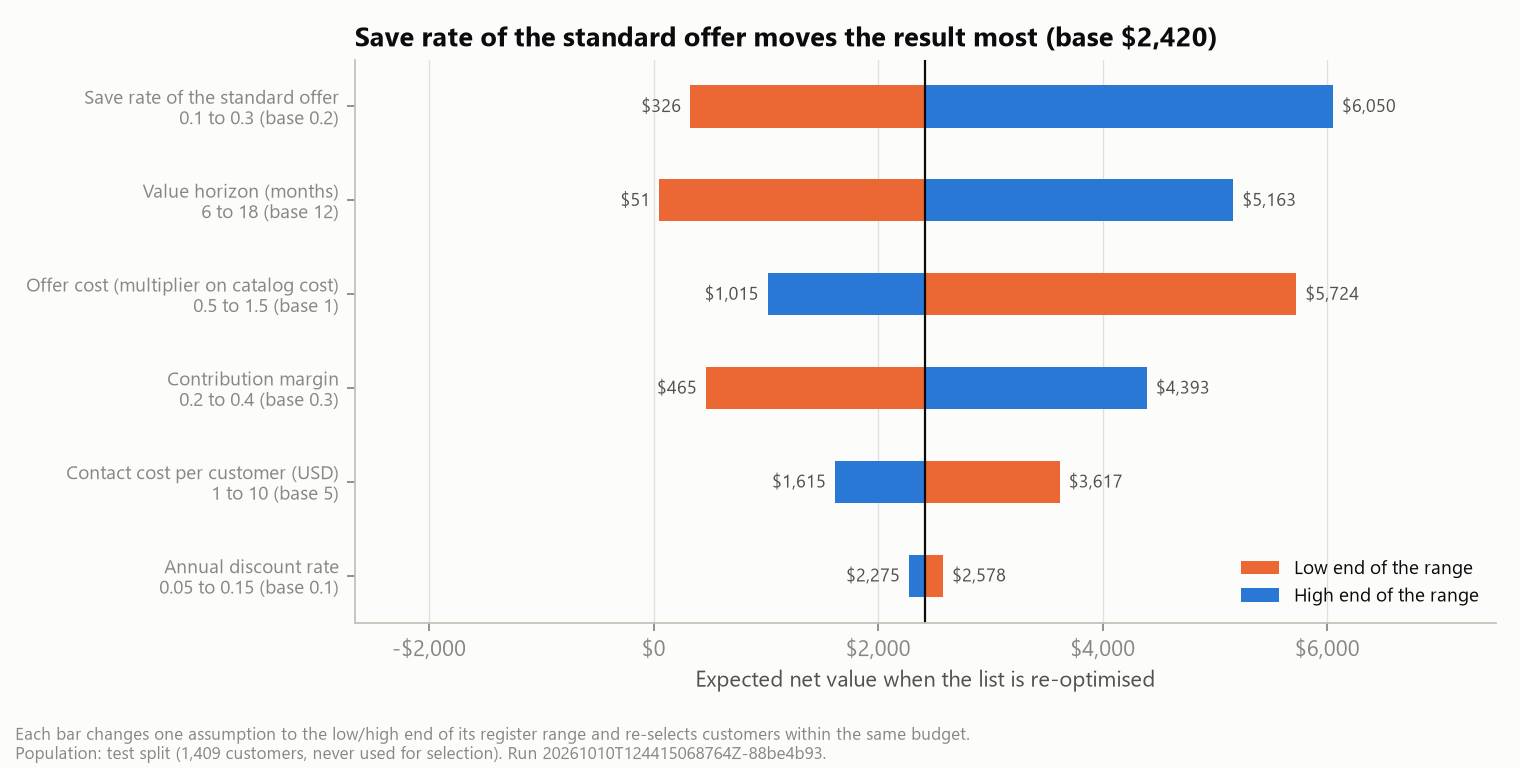

In [2]:
display(pd.read_csv(run / "tornado.csv")[["label", "low", "high", "base", "net_low_retarget", "net_high_retarget", "net_low_fixed", "net_high_fixed"]])
display(Image(filename=str(ROOT / "reports/figures/tornado.png")))

**Interpretation.** Save rate of the standard offer and value horizon (months) move the result most. *Retarget* re-selects customers under the new assumption; *fixed* keeps today's list. A re-optimised plan cannot go below zero (it would contact nobody), a frozen list can.

## Save rate x offer cost

cost_multiplier,0.50,0.75,1.00,1.25,1.50,2.00
fixed: save rate / cost x,,,,,,
0.05,-722.0,-1407.0,-2092.0,-2777.0,-3461.0,-4831.0
0.10,782.0,97.0,-588.0,-1273.0,-1957.0,-3327.0
0.15,2286.0,1601.0,916.0,231.0,-453.0,-1823.0
0.20,3790.0,3105.0,2420.0,1735.0,1051.0,-319.0
0.25,5294.0,4609.0,3924.0,3239.0,2555.0,1185.0
0.30,6798.0,6113.0,5428.0,4743.0,4059.0,2689.0
0.40,9806.0,9121.0,8436.0,7751.0,7067.0,5697.0


cost_multiplier,0.50,0.75,1.00,1.25,1.50,2.00
retarget: save rate / cost x,,,,,,
0.05,1109.0,179.0,4.0,0.0,0.0,0.0
0.10,2641.0,1160.0,326.0,40.0,0.0,0.0
0.15,4178.0,2325.0,1210.0,480.0,109.0,0.0
0.20,5724.0,3630.0,2420.0,1605.0,1015.0,286.0
0.25,7685.0,5507.0,4154.0,3192.0,2463.0,1413.0
0.30,10045.0,7655.0,6050.0,4867.0,3961.0,2650.0
0.40,15298.0,12116.0,9897.0,8244.0,6976.0,5146.0


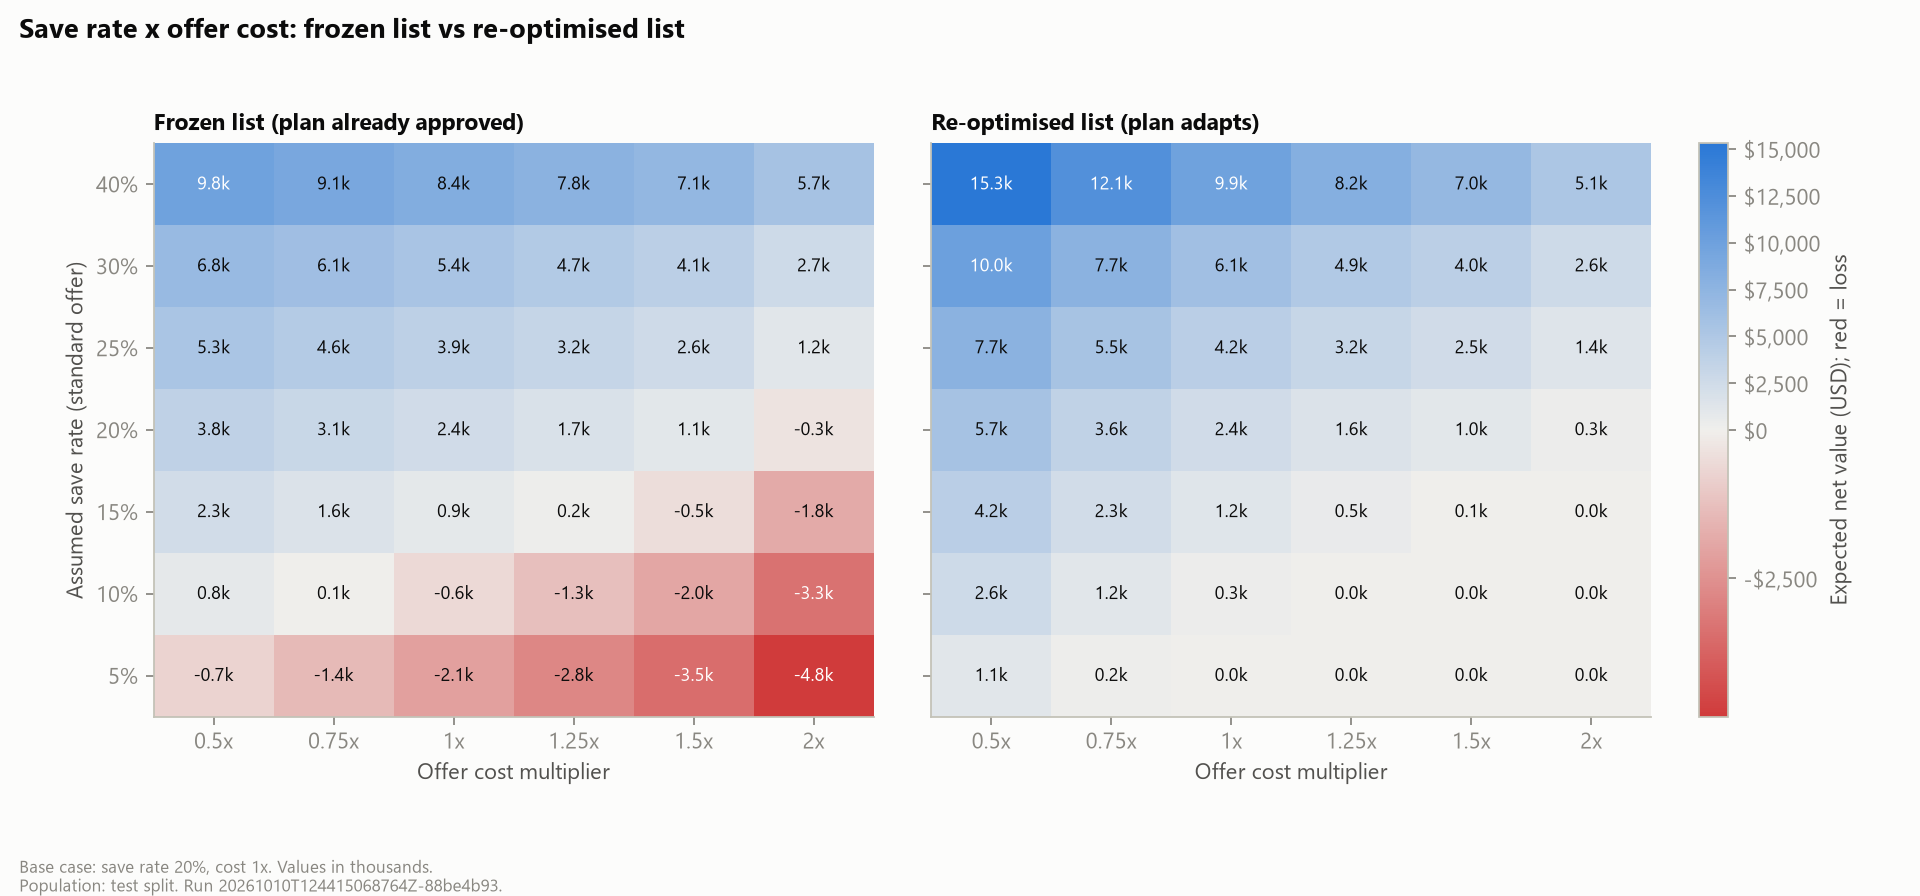

,scenario,overrides,selected_count,cost,expected_net_value,roi,expected_saved,fixed_expected_net_value,fixed_roi
0,pessimistic,"{""save_rate"": 0.1, ""offer_cost_multiplier"": 1....",0,0.0,0.000,NaN,0.000,-2797.097,-0.603
1,base,{},152,3499.0,2420.147,0.692,17.910,2420.147,0.692
2,optimistic,"{""save_rate"": 0.3, ""offer_cost_multiplier"": 0....",313,3500.0,18525.193,5.293,46.742,12338.316,5.232


{'strategy': 'segment_offers',
 'selected_count': 152,
 'save_rate_multiplier': 0.5911324988044198,
 'break_even_default_save_rate': 0.11822649976088395,
 'offer_cost_multiplier': 1.8835877088631303,
 'break_even_default_offer_cost': 37.671754177262606,
 'minimum_viable_save_rate': 0.08910844091995469,
 'break_even_probability_quantiles': {'p10': 0.2943546409333618,
  'p25': 0.36409404816988133,
  'p50': 0.5432991995188771,
  'p75': 1.0859460700643673,
  'p90': 1.832907746055055}}

In [3]:
sens = pd.read_csv(run / "sensitivity.csv")
grid = sens.query("axis == 'save_rate x offer_cost'")
for mode in ["fixed", "retarget"]:
    display(grid.query("mode == @mode").pivot(index="parameter", columns="cost_multiplier", values="expected_net_value").round(0).rename_axis(f"{mode}: save rate / cost x"))
display(Image(filename=str(ROOT / "reports/figures/sensitivity_heatmap.png")))
display(pd.read_csv(run / "scenarios.csv"))
display(read_json(run / "break_even.json"))

**Interpretation.** Break-even save rate of the recommended list: 11.8%; below 8.9% nobody has positive expected value. Pessimistic / base / optimistic: $0 / $2,420 / $18,525.

## Budget optimisation across campaign sizes

,budget_share,selected_count,cost,expected_net_value,marginal_roi
0,0.00,0,0.0,0.000,NaN
1,0.02,40,696.0,724.190,1.041
2,0.04,75,1400.0,1261.366,0.763
3,0.06,108,2099.0,1704.088,0.633
4,0.08,136,2799.0,2088.502,0.549
5,0.10,156,3500.0,2417.614,0.469
6,0.12,177,4224.0,2709.904,0.404
7,0.14,202,4925.0,2946.512,0.338
8,0.16,222,5625.0,3141.934,0.279
9,0.18,242,6325.0,3304.436,0.232


{'strategy': 'segment_offers',
 'population': 'validation',
 'hurdle_marginal_roi': 0.1,
 'recommended_share': 0.24,
 'recommended_budget': 8450.0,
 'expected_net_value': 3661.4947654074053,
 'roi': 0.4334155735567478,
 'marginal_roi': 0.1376527762099179,
 'net_maximising_share': 0.32,
 'net_maximising_value': 3784.0193673633175}

{'strategy': 'segment_offers',
 'budget_share': 0.24,
 'budget': 8450.0,
 'selected_count': 310,
 'cost': 8450.0,
 'remaining_budget': 0.0,
 'expected_saved': 40.60402788722108,
 'expected_retained_value': 12141.75299891494,
 'expected_net_value': 3691.7529989149416,
 'roi': 0.43689384602543685,
 'expected_precision': 0.5981078929635952,
 'precision_contacted': 0.567741935483871,
 'label_based_simulated_net': 3285.544662492981,
 'high_risk_high_value_count': 51,
 'high_risk_high_value_coverage': 1.0,
 'scenario_id': '5433f51f5022',
 'solver_status': 'optimal'}

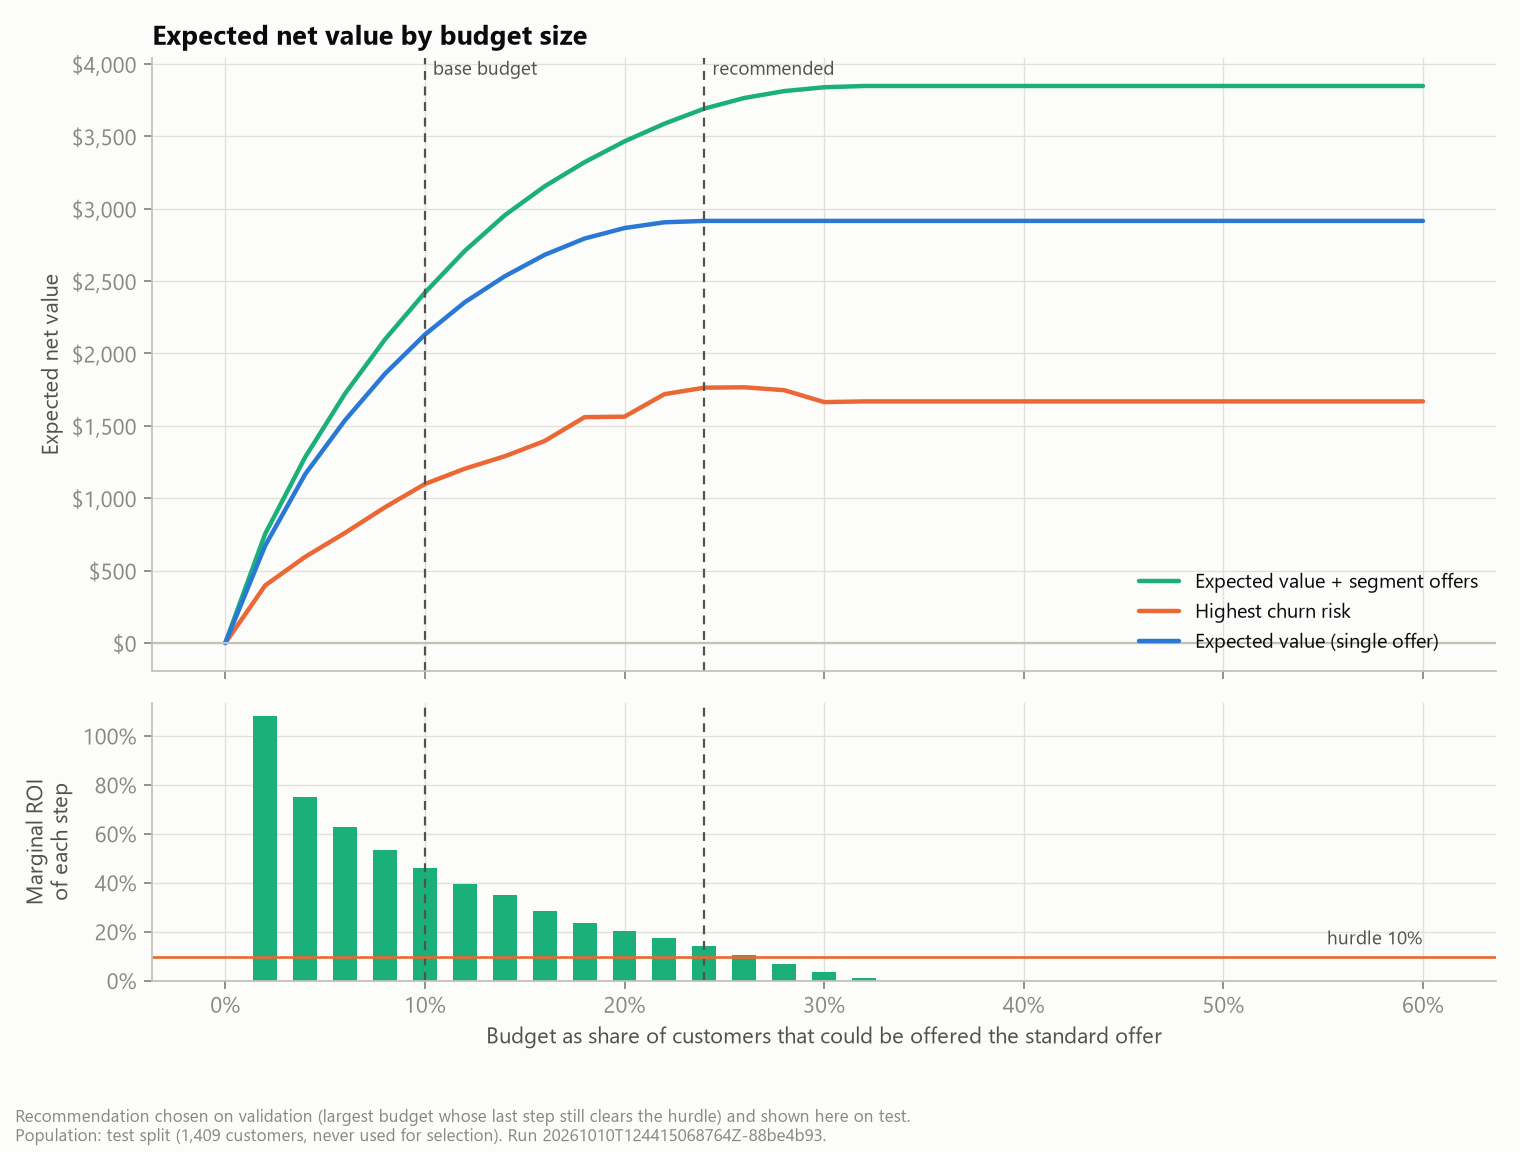

In [4]:
curve = pd.read_csv(run / "budget_curve.csv")
display(curve.query("population == 'validation'")[["budget_share", "selected_count", "cost", "expected_net_value", "marginal_roi"]])
display(read_json(run / "validation_decisions.json")["budget_recommendation"])
display(read_json(run / "recommended_campaign.json"))
display(Image(filename=str(ROOT / "reports/figures/profit_curve.png")))

**Interpretation.** On validation, the largest budget whose last step still earns 10% is 24% of customers. On test this gives 310 offers, $8,450 cost and $3,692 expected net value.

## Fairness and customer experience

,strategy,attribute,group,customers,selection_rate,ratio_to_reference,ratio_lower_95,ratio_upper_95,risk_adjusted_ratio,review_flag,explained_by_risk
0,risk,gender,Female,714,0.105,1.123,0.802,1.538,1.015,False,False
1,risk,gender,Male,695,0.094,1.000,1.000,1.000,1.000,False,False
2,risk,SeniorCitizen,0,1170,0.080,1.000,1.000,1.000,1.000,False,False
3,risk,SeniorCitizen,1,239,0.192,2.396,1.709,3.264,1.011,True,True
4,risk,tenure_segment,developing,204,0.039,0.395,0.159,0.673,1.007,True,True
5,risk,tenure_segment,loyal,774,0.001,0.013,0.000,0.041,1.007,True,True
6,risk,tenure_segment,new,431,0.304,3.059,2.834,3.331,1.111,True,True
7,risk,Contract,Month-to-month,786,0.178,1.793,1.718,1.879,1.250,True,False
8,risk,Contract,One year,284,0.000,0.000,0.000,0.000,0.000,True,False
9,risk,Contract,Two year,339,0.000,0.000,0.000,0.000,0.000,True,False


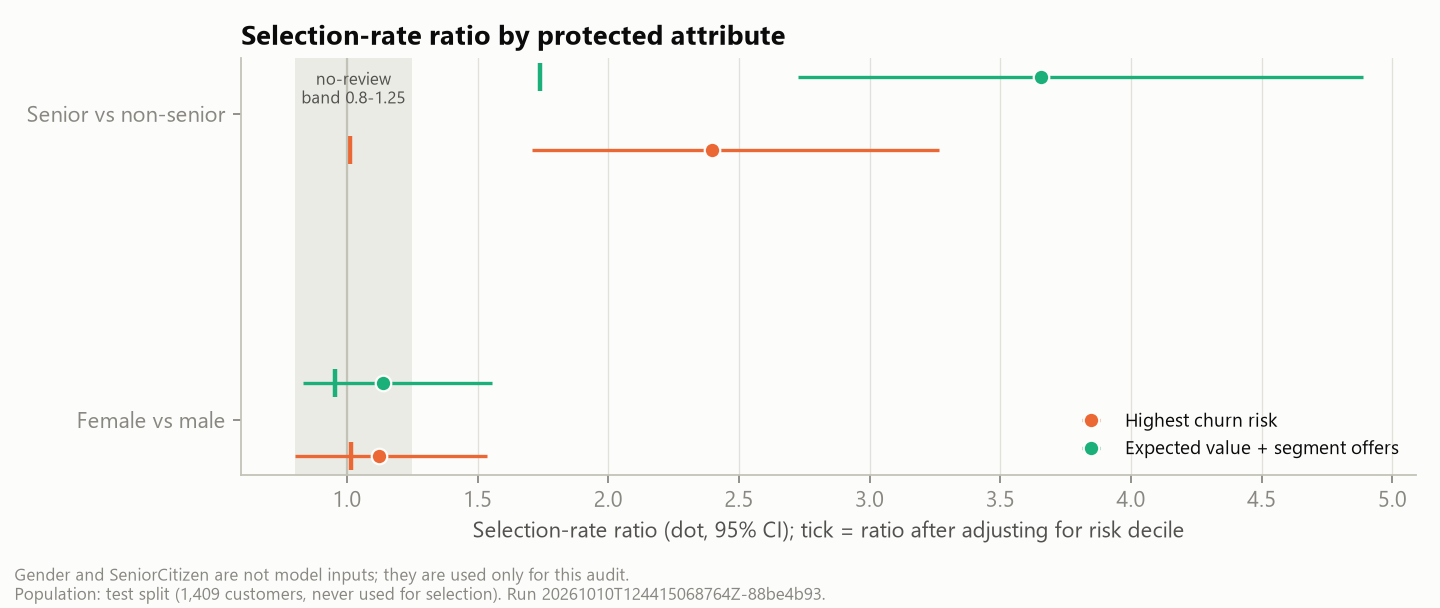

In [5]:
fair = pd.read_csv(run / "fairness.csv")
display(fair[["strategy", "attribute", "group", "customers", "selection_rate", "ratio_to_reference", "ratio_lower_95", "ratio_upper_95", "risk_adjusted_ratio", "review_flag", "explained_by_risk"]])
display(Image(filename=str(ROOT / "reports/figures/fairness.png")))

**Interpretation.** Seniors are contacted 3.66x as often as non-seniors; within the same risk decile the ratio is 1.74x. Risk explains most of the gap and value (higher bills) the rest. Neither gender nor age is a model input. Because an offer is both a discount and an intrusion, the gap is flagged for human review each wave rather than corrected mechanically.

## Pilot sizing

In [6]:
display(read_json(run / "pilot_plan.json"))
display(pd.read_csv(run / "pilot_power.csv"))

{'control_churn_expected': 0.5981078929635952,
 'observed_churn_test_list': 0.567741935483871,
 'recommended_share': 0.24,
 'base_population': 7043,
 'list_size_per_wave': 1690,
 'arm_size_per_wave': 845,
 'minimum_detectable_save_rate_one_wave': 0.11293335716477239,
 'alpha': 0.05,
 'power': 0.8,
 'holdout_share': 0.5,
 'outcome_window_days': 90}

,assumed_save_rate,control_churn,treated_churn,customers_per_arm,total_customers,arm_size_per_wave,waves_needed
0,0.05,0.598,0.568,4266.0,8532.0,845,6
1,0.10,0.598,0.538,1076.0,2152.0,845,2
2,0.15,0.598,0.508,481.0,962.0,845,1
3,0.20,0.598,0.478,272.0,544.0,845,1
4,0.30,0.598,0.419,121.0,242.0,845,1


**So what.** One wave of 1,690 customers with half held out can detect a save rate of about 11% or more, close to the break-even. Measuring it is the decisive next step: it replaces the most influential assumption with evidence.